In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from google.colab import files

Saving felfel-dolme.jpg to felfel-dolme.jpg
Input Image: felfel-dolme.jpg
Image Shape: (741, 1280, 3)


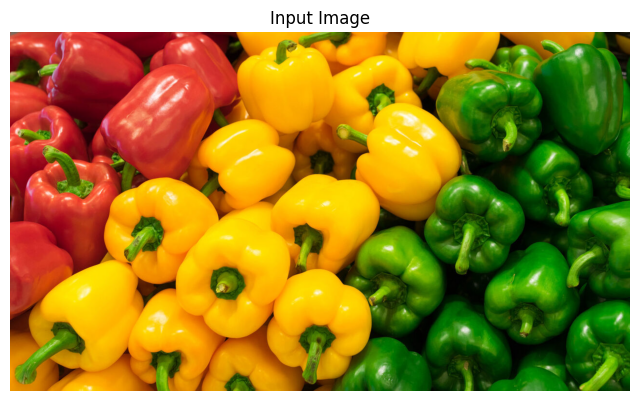

In [3]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

if len(uploaded_names) == 0:
  raise ValueError("No File Uploaded")

image_name = next(
    (
        name for name in uploaded_names if 'felfel' in name.lower()
    ),
    uploaded_names[0]
    )

image_path = '/content/' + image_name
img = cv2.imread(image_path)

if img is None:
  raise ValueError("Invalid Image")

print('Input Image:', image_name)
print('Image Shape:', img.shape)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('off')

plt.show()

In [4]:
n_clusters = 5

flat_img = img.reshape((-1, 3)).astype(np.float32)

kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans.fit(flat_img)

dominant_colors = np.array(kmeans.cluster_centers_, dtype=np.uint8)
labels = kmeans.labels_

print('Dominant Colors:', dominant_colors)
print('Dominant Colors Shape:', dominant_colors.shape)

Dominant Colors: [[ 28  59 183]
 [  2 179 245]
 [ 10 138  75]
 [129 189 226]
 [  2  57  21]]
Dominant Colors Shape: (5, 3)


In [6]:
percentages = np.bincount(labels) / len(flat_img)

print('Percentages:', percentages)
print('Percentages Shape:', percentages.shape)

for index, percentage in enumerate(percentages):
  print(f'Color {index}: {percentage * 100:.2f}%')

p_and_c = sorted(zip(percentages, dominant_colors), reverse=True, key=lambda item: item[0])

print('Sorted Percentages And Colors:', p_and_c)
print('Sorted Percentages And Colors Shape:', len(p_and_c))

for index, (percentage, color) in enumerate(p_and_c, start=1):
  print(f'Color: {color}, Percentage: {percentage * 100:.2f}%')

Percentages: [0.21081942 0.33720479 0.1491692  0.02772014 0.27508645]
Percentages Shape: (5,)
Color 0: 21.08%
Color 1: 33.72%
Color 2: 14.92%
Color 3: 2.77%
Color 4: 27.51%
Sorted Percentages And Colors: [(np.float64(0.33720479082321186), array([  2, 179, 245], dtype=uint8)), (np.float64(0.27508645411605936), array([ 2, 57, 21], dtype=uint8)), (np.float64(0.21081941632928475), array([ 28,  59, 183], dtype=uint8)), (np.float64(0.14916919703103915), array([ 10, 138,  75], dtype=uint8)), (np.float64(0.02772014170040486), array([129, 189, 226], dtype=uint8))]
Sorted Percentages And Colors Shape: 5
Color: [  2 179 245], Percentage: 33.72%
Color: [ 2 57 21], Percentage: 27.51%
Color: [ 28  59 183], Percentage: 21.08%
Color: [ 10 138  75], Percentage: 14.92%
Color: [129 189 226], Percentage: 2.77%


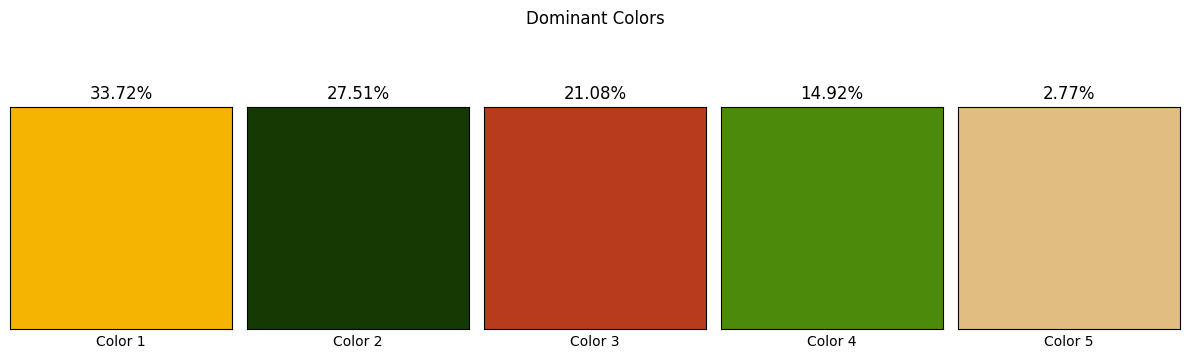

In [7]:
color_block = np.ones((100, 100, 3), dtype=np.uint8)

plt.figure(figsize=(12, 4))

for index, (percentage, color) in enumerate(p_and_c):
  color_block[:] = color[::-1]
  plt.subplot(1, n_clusters, index + 1)
  plt.imshow(color_block)
  plt.title(f'{percentage * 100:.2f}%')
  plt.xticks([])
  plt.yticks([])
  plt.xlabel(f'Color {index + 1}')

plt.suptitle('Dominant Colors')
plt.tight_layout()
plt.show()

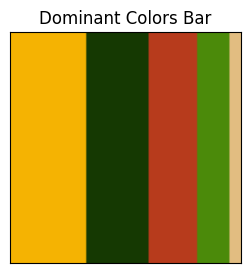

In [8]:
bar_width = 100
bar = np.ones((100, bar_width, 3), dtype=np.uint8)

start = 0

for index, (percentage, color) in enumerate(p_and_c):
  if index == len(p_and_c) - 1:
    end = img.shape[1]

  else:
    end = start + int(bar_width * percentage)

  bar[:, start:end] = color[::-1]
  start = end

plt.figure(figsize=(14, 3))
plt.imshow(bar)
plt.title('Dominant Colors Bar')
plt.xticks([])
plt.yticks([])

plt.show()

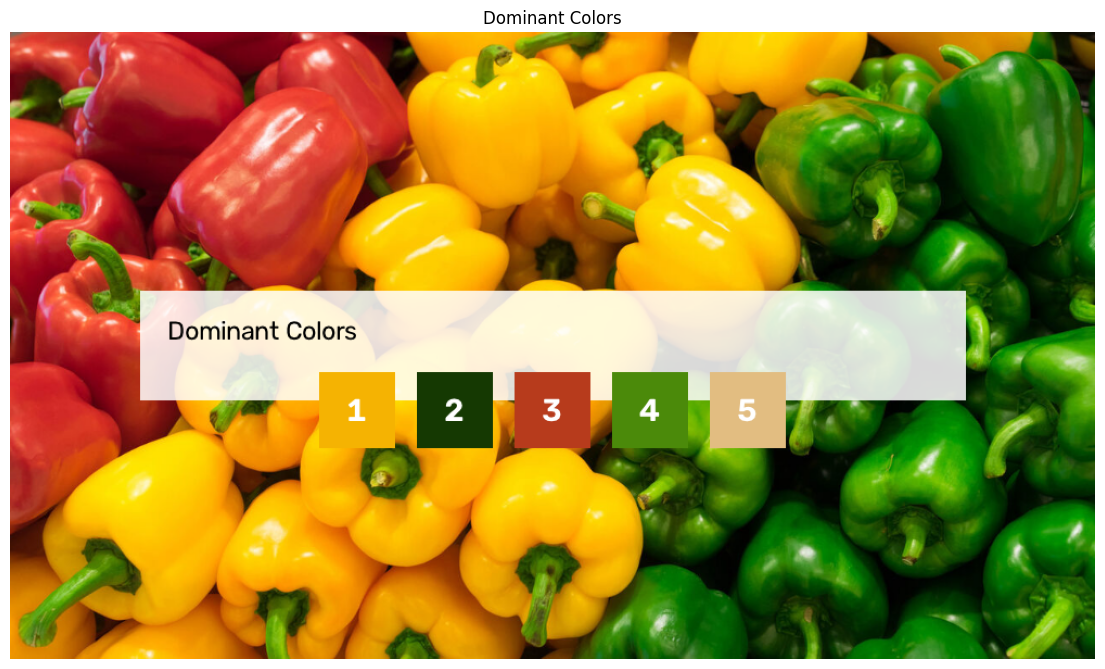

In [10]:
display_width = 1000
scale = display_width / img.shape[1]
display_height = int(img.shape[0] * scale)

resized_img = cv2.resize(img, (display_width, display_height), interpolation=cv2.INTER_LINEAR)

final_image = resized_img.copy()

panel_width = min(760, display_width - 80)
panel_height = 100
panel_x = (display_width - panel_width) // 2
panel_y = max(20, (display_height - panel_height) // 2)

overly = final_image.copy()
cv2.rectangle(overly, (panel_x, panel_y), (panel_x + panel_width, panel_y + panel_height), (255, 255, 255), -1)
final_image = cv2.addWeighted(final_image, 0.15, overly, 0.85, 0)

cv2.putText(
    final_image,
    'Dominant Colors',
    (panel_x + 25, panel_y + 45),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 0),
    1,
    cv2.LINE_AA
)

swatch_size = 70
spacing = 20
total_width = n_clusters * swatch_size + (n_clusters - 1) * spacing
swatch_x = (display_width - total_width) // 2
swatch_y = panel_y + 75

for index, (percentage, color) in enumerate(p_and_c):
  x1 = swatch_x + (index * (swatch_size + spacing))
  x2 = x1 + swatch_size
  final_image[swatch_y:swatch_y + swatch_size, x1:x2] = color
  cv2.putText(
      final_image,
      str(index + 1),
      (x1 + 25, swatch_y + 45),
      cv2.FONT_HERSHEY_DUPLEX,
      1,
      (255, 255, 255),
      1, cv2.LINE_AA
  )

plt.figure(figsize=(14, 10))

plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.title('Dominant Colors')
plt.axis('off')

plt.show()

In [12]:
cv2.imwrite(
    '/content/dominant-colors-result.png',
    final_image
)
cv2.imwrite(
    '/content/dominant-colors-bar.png',
    cv2.cvtColor(bar, cv2.COLOR_RGB2BGR)
)

print('Saved: /content/dominant-colors-result.png')
print('Saved: /content/dominant-colors-bar.png')

files.download('/content/dominant-colors-result.png')
files.download('/content/dominant-colors-bar.png')

print('Downloaded: /content/dominant-colors-result.png')
print('Downloaded: /content/dominant-colors-bar.png')

Saved: /content/dominant-colors-result.png
Saved: /content/dominant-colors-bar.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/dominant-colors-result.png
Downloaded: /content/dominant-colors-bar.png
